# Entrega 3 · Estilos de juego ATP: grupos sin etiqueta

**Grupo 5K10-05 · Ciencia de Datos · UTN FRM · 2026**

Este notebook corre **de arriba hacia abajo**, con una semilla única (`SEMILLA = 42`) pasada a todo lo que la
acepta, y conserva sus salidas. Funciona igual en local y en Google Colab: la primera celda de datos busca los
CSV en el repositorio y, si no están, los baja de Drive con `gdown` (o los pide por `files.upload()`).

## Hoja de ruta

| Parte | Qué pasa | Qué deja |
|---|---|---|
| **1** | La unidad y las columnas de la distancia | 1.224 perfiles jugador–superficie, siete rasgos y la escala como paso del pipeline |
| **2** | Elegir *k* | la curva de inercia (con *k* = 1), el silhouette, la estabilidad y una decisión declarada |
| **3** | Los grupos | tamaño, perfil, nombre defendido con una columna, jugadores conocidos de cada uno |
| **4** | Una proyección para mirar | PCA en dos componentes, siluetas y DBSCAN: ¿grupos separados o cortes de un degradé? |
| **5** | Lo que domina | qué pasa si se saca una columna, si no se escala, si se agrega la redundante |
| **6** | Lo que no apareció | lo que esperábamos y los datos no dieron |
| **7** | Salidas para la Entrega 4 | pipeline guardado, asignación de estilos y parámetros para la app |

## Qué cambió desde la Entrega 2

El docente pidió variar las habilidades de las hipótesis: se reemplazaron **H4** (ahora devolución y ganador más
allá del ranking) y **H5** (ahora compromiso entre saque y devolución, con r ≈ −0,58 entre aces y puntos ganados
al resto), y se conservaron H1, H2 y H3. El objetivo de esta entrega no cambió: los siete rasgos de saque y
devolución que cerró la Entrega 2 son las columnas de la distancia, y esta vez se decide *k* y se describen los grupos.

## Qué se evalúa en un proyecto sin objetivo

Las columnas de la distancia elegidas y escaladas, con el motivo; *k* elegido con una medida interna y la curva
mostrada; los grupos descriptos con un nombre defendible; la decisión sobre lo que domina; una proyección en PCA;
y lo que no apareció. **Todo adentro de un pipeline**: elegir y escalar las columnas es el primer paso, y agrupar el
último. Un grupo no es una categoría que existía y se descubrió: es un corte que el algoritmo hizo porque se lo
pidieron, y si tiene sentido, lo tiene por la descripción y no por el silhouette.

## Antes de empezar: preámbulo y datos

La celda siguiente fija la semilla, las rutas y la forma de conseguir los datos. Los dos CSV son los canónicos que
produce el DAG de Airflow (`atp_jugadores_2026-09-23.csv` y `atp_partidos_2026-09-23.csv`). Para Colab, pegar en
`ID_DRIVE_JUGADORES` e `ID_DRIVE_PARTIDOS` el identificador de cada archivo en Drive; si se dejan sin completar,
Colab pedirá subir los archivos a mano.

In [1]:
import os, sys, json, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

SEMILLA = 42                      # la misma en todo el notebook
np.random.seed(SEMILLA)

# Identificadores de Drive para Colab (se dejan sin completar si los archivos están en el repositorio)
ID_DRIVE_JUGADORES = "PEGAR_ID_DRIVE_JUGADORES"
ID_DRIVE_PARTIDOS  = "PEGAR_ID_DRIVE_PARTIDOS"
ARCHIVOS = {"jugadores": ("atp_jugadores_2026-09-23.csv", ID_DRIVE_JUGADORES),
            "partidos":  ("atp_partidos_2026-09-23.csv",  ID_DRIVE_PARTIDOS)}


def buscar_local(nombre):
    """Busca el archivo hacia arriba desde la carpeta actual: sirve corriendo desde entrega3/ o desde la raíz."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for rel in ("airflow-atp/include/output", "include/output", "datos", "."):
            ruta = base / rel / nombre
            if ruta.exists():
                return ruta
    return None


def obtener(nombre, id_drive):
    """Ruta local si existe; si no, la baja de Drive con gdown; si no hay ID y es Colab, pide subirla."""
    ruta = buscar_local(nombre)
    if ruta is not None:
        return ruta
    destino = Path.cwd() / nombre
    if not id_drive.startswith("PEGAR"):
        try:
            import gdown
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
            import gdown
        gdown.download(id=id_drive, output=str(destino), quiet=True)
    elif "google.colab" in sys.modules:
        from google.colab import files
        print(f"Subí {nombre}")
        files.upload()
    if not destino.exists():
        raise FileNotFoundError(f"No encuentro {nombre}: ponelo en airflow-atp/include/output/, "
                                "completá el ID de Drive o subilo a mano.")
    return destino


RUTAS = {clave: obtener(*valor) for clave, valor in ARCHIVOS.items()}

# Carpeta de salidas: junto al repositorio si se lo encuentra; si no, en la carpeta actual (Colab)
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "airflow-atp").exists()), None)
OUT = (RAIZ / "entrega3" / "resultados") if RAIZ else (Path.cwd() / "resultados")
OUT.mkdir(parents=True, exist_ok=True)

# Estilo de los gráficos y paleta de Okabe-Ito (distinguible con daltonismo), como en las prácticas
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .16, "font.size": 10, "axes.titleweight": "bold"})
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X"]
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


def texto(s):
    display(Markdown(s))


df = pd.read_csv(RUTAS["jugadores"], dtype={"id-jugador": "string"}, low_memory=False)
partidos = pd.read_csv(RUTAS["partidos"], usecols=["surface", "anio", "fecha"], low_memory=False)

assert df["id-jugador"].is_unique, "una fila por jugador"
# Trazabilidad: las participaciones del CSV de jugadores salen de los partidos en cemento, clay y grass
participaciones = 2 * partidos["surface"].isin(["Hard", "Clay", "Grass"]).sum()
cubierto = df["partidos-totales"].sum() / participaciones
assert 0.95 < cubierto <= 1.0
texto(f"**Datos:** {len(df):,} jugadores × {df.shape[1]} columnas, construidos a partir de {len(partidos):,} partidos "
      f"({partidos['anio'].min()}–{partidos['anio'].max()}). Las participaciones de los jugadores cubren "
      f"el {cubierto:.1%} de las de los partidos en superficies válidas (el resto son jugadores con menos de "
      f"3 partidos o sin estadísticas). Salidas en `{OUT.name}/`.")

**Datos:** 1,450 jugadores × 157 columnas, construidos a partir de 77,474 partidos (2000–2025). Las participaciones de los jugadores cubren el 97.7% de las de los partidos en superficies válidas (el resto son jugadores con menos de 3 partidos o sin estadísticas). Salidas en `resultados/`.

## Parte 1 — La unidad y las columnas de la distancia

### 1.1 Qué es una fila

El CSV tiene una fila por jugador, pero un mismo jugador no juega igual en cemento, en clay y en grass: la
Entrega 2 decidió que **la unidad es el perfil jugador–superficie**. Se pasa de formato ancho a largo (tres filas
por jugador) y se conservan solo los perfiles con información confiable:

- al menos **20 partidos** en esa superficie (H1: con menos, los valores son más extremos y menos estables),
- al menos **80 % de cobertura** de estadísticas de saque y de devolución,
- las siete tasas definidas.

La superficie **identifica la fila pero no entra a la distancia**; las victorias, los títulos y los partidos
tampoco, y se guardan aparte solo para *mirar* los grupos después.

In [2]:
SUPERFICIES = ["cemento", "clay", "grass"]
# nombre interno -> nombre de la columna en el CSV (sin el sufijo de superficie)
TASAS = {
    "tasa_aces":            "tasa-aces",
    "tasa_dobles_faltas":   "tasa-dobles-faltas",
    "primer_saque_dentro":  "tasa-primer-saque-dentro",
    "efectividad_primero":  "efectividad-primer-saque",
    "efectividad_segundo":  "efectividad-segundo-saque",
    "bp_salvados":          "tasa-break-points-salvados",
    "puntos_ganados_resto": "tasa-puntos-ganados-resto",
    "bp_convertidos":       "tasa-break-points-convertidos",
}


def perfiles_jugador_superficie(jugadores):
    """Formato largo: una fila por jugador y superficie, con las tasas de esa superficie."""
    partes = []
    for sup in SUPERFICIES:
        bloque = pd.DataFrame({
            "id": jugadores["id-jugador"], "nombre": jugadores["nombre-jugador"], "superficie": sup,
            "partidos": jugadores[f"partidos-{sup}"], "winrate": jugadores[f"tasa-victorias-{sup}"],
            "cobertura_saque": jugadores[f"cobertura-saque-{sup}"],
            "cobertura_resto": jugadores[f"cobertura-resto-{sup}"],
            "titulos": jugadores[[c for c in jugadores.columns if c.startswith("titulos-") and c.endswith(f"-{sup}")]].sum(axis=1),
        })
        for interno, columna in TASAS.items():
            bloque[interno] = jugadores[f"{columna}-{sup}"]
        partes.append(bloque)
    return pd.concat(partes, ignore_index=True)


largo = perfiles_jugador_superficie(df)
confiable = (largo["partidos"].ge(20) & largo["cobertura_saque"].ge(0.80) & largo["cobertura_resto"].ge(0.80)
             & largo[list(TASAS)].notna().all(axis=1))
X = largo[confiable].reset_index(drop=True)

resumen = largo.assign(confiable=confiable).groupby("superficie").agg(
    perfiles=("id", "size"), con_partidos=("partidos", lambda s: int(s.gt(0).sum())), confiables=("confiable", "sum"))
display(resumen.T)
texto(f"**Unidad de trabajo:** {len(X):,} perfiles jugador–superficie de {X['id'].nunique():,} jugadores distintos. "
      f"Cemento {int((X.superficie == 'cemento').sum())}, clay {int((X.superficie == 'clay').sum())}, "
      f"grass {int((X.superficie == 'grass').sum())}.")

superficie,cemento,clay,grass
perfiles,1450,1450,1450
con_partidos,1357,1249,864
confiables,514,451,259


**Unidad de trabajo:** 1,224 perfiles jugador–superficie de 582 jugadores distintos. Cemento 514, clay 451, grass 259.

### 1.2 Las siete columnas de la distancia, y las que quedan afuera

Qué entra en la distancia es la primera decisión del modelo y la que más cambia el resultado. La pregunta del
proyecto es sobre **estilos de saque y devolución**, así que entran las tasas que describen *cómo* se juega, no
cuánto se gana:

| Columna | Qué mide | Por qué entra |
|---|---|---|
| `tasa_aces` | aces / puntos de saque | potencia del saque |
| `tasa_dobles_faltas` | dobles faltas / puntos de saque | riesgo y regularidad del saque |
| `primer_saque_dentro` | primeros saques dentro / puntos de saque | regularidad del primer servicio |
| `efectividad_segundo` | puntos ganados con segundo saque | solidez cuando el primero falla |
| `bp_salvados` | break points salvados / enfrentados | aguante al sacar bajo presión |
| `puntos_ganados_resto` | puntos que el rival no ganó al sacar | calidad de la devolución |
| `bp_convertidos` | break points convertidos / oportunidades | filo de la devolución bajo presión |

Quedan **afuera**:

- `efectividad_primero`: es casi redundante con `tasa_aces` (H2 de la Entrega 2). Si entrara, el saque potente
  pesaría doble. Más abajo se mide qué pasa si se la vuelve a poner.
- `winrate` y títulos: son *resultados*, no estilo. Si entraran, el grupo "ganadores" saldría solo (circular).
  Se reservan para mirar si algún estilo es superior.
- `partidos`, `cobertura_*`: son filtros de calidad, no habilidad.
- `superficie`: define la fila y la estandarización, no la distancia.

La matriz de correlación dice cuánto se solapan las siete:

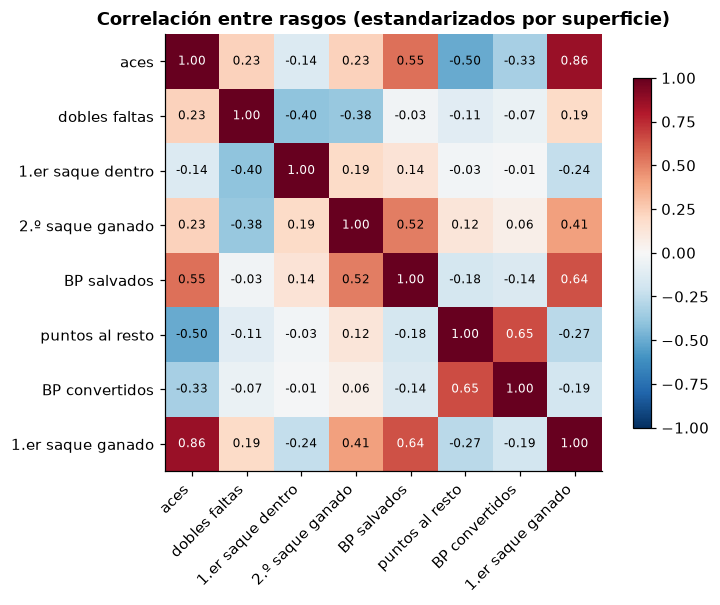

,,correlación
tasa_aces,efectividad_primero,0.860
puntos_ganados_resto,bp_convertidos,0.650
bp_salvados,efectividad_primero,0.640
tasa_aces,bp_salvados,0.550
efectividad_segundo,bp_salvados,0.520


In [3]:
COLUMNAS = ["tasa_aces", "tasa_dobles_faltas", "primer_saque_dentro", "efectividad_segundo",
            "bp_salvados", "puntos_ganados_resto", "bp_convertidos"]
ETIQUETAS = {"tasa_aces": "aces", "tasa_dobles_faltas": "dobles faltas", "primer_saque_dentro": "1.er saque dentro",
             "efectividad_primero": "1.er saque ganado", "efectividad_segundo": "2.º saque ganado",
             "bp_salvados": "BP salvados", "puntos_ganados_resto": "puntos al resto", "bp_convertidos": "BP convertidos"}

# la correlación se mira sobre valores estandarizados dentro de cada superficie
z_vista = X.groupby("superficie")[COLUMNAS + ["efectividad_primero"]].transform(lambda s: (s - s.mean()) / s.std())
corr = z_vista.corr()
orden = COLUMNAS + ["efectividad_primero"]
corr = corr.loc[orden, orden]

fig, ax = plt.subplots(figsize=(7.2, 5.6))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(orden)), [ETIQUETAS[c] for c in orden], rotation=45, ha="right")
ax.set_yticks(range(len(orden)), [ETIQUETAS[c] for c in orden])
for i in range(len(orden)):
    for j in range(len(orden)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > .6 else "black")
ax.grid(False); fig.colorbar(im, shrink=.8)
ax.set_title("Correlación entre rasgos (estandarizados por superficie)")
plt.tight_layout(); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
pares.head(5).rename("correlación").to_frame().round(2)

In [4]:
r1 = corr.loc["tasa_aces", "efectividad_primero"]
r2 = corr.loc["puntos_ganados_resto", "bp_convertidos"]
r3 = corr.loc["tasa_aces", "puntos_ganados_resto"]
texto(f"`efectividad_primero` y `tasa_aces` correlacionan {r1:.2f}: por eso la primera queda afuera. "
      f"Entre las siete, las dos de devolución (`puntos_ganados_resto` y `bp_convertidos`) se parecen {r2:.2f} y "
      f"aces contra puntos al resto da {r3:.2f}, el compromiso saque–devolución que anticipó H5 de la Entrega 2. "
      "Entre las siete ninguna pareja pasa de 0,7, así que no hay una columna que sea copia de otra; sí hay un **eje** "
      "(saque potente contra devolución) que va a pesar mucho, y se vuelve a mirar en la Parte 5.")

`efectividad_primero` y `tasa_aces` correlacionan 0.86: por eso la primera queda afuera. Entre las siete, las dos de devolución (`puntos_ganados_resto` y `bp_convertidos`) se parecen 0.65 y aces contra puntos al resto da -0.50, el compromiso saque–devolución que anticipó H5 de la Entrega 2. Entre las siete ninguna pareja pasa de 0,7, así que no hay una columna que sea copia de otra; sí hay un **eje** (saque potente contra devolución) que va a pesar mucho, y se vuelve a mirar en la Parte 5.

### 1.3 La escala también es parte del modelo

K-means mide distancias. Si una columna va de 0 a 100 y otra de 0 a 100.000, la segunda decide sola. Acá todas son
tasas entre 0 y 1, pero sus **desvíos** son distintos (las dobles faltas varían tres veces menos que el primer
saque dentro), y hay un segundo problema que es propio de este dataset: **los niveles dependen de la superficie**.
En grass se sacan más aces y se devuelve menos que en clay, así que sin corregir eso los grupos se llamarían
"grass" y "clay" en vez de describir estilos.

In [5]:
nivel = X.groupby("superficie")[COLUMNAS].mean().T
nivel["desvío general"] = X[COLUMNAS].std()
nivel["media grass / clay"] = nivel["grass"] / nivel["clay"]
display((nivel[["cemento", "clay", "grass", "desvío general", "media grass / clay"]]).rename(index=ETIQUETAS).round(3))

superficie,cemento,clay,grass,desvío general,media grass / clay
aces,0.080,0.053,0.094,0.037,1.768
dobles faltas,0.040,0.036,0.039,0.012,1.096
1.er saque dentro,0.601,0.610,0.624,0.041,1.023
2.º saque ganado,0.500,0.494,0.520,0.026,1.051
BP salvados,0.603,0.589,0.636,0.041,1.080
puntos al resto,0.356,0.381,0.346,0.028,0.907
BP convertidos,0.381,0.400,0.368,0.038,0.919


Las medias por superficie cambian bastante (los aces en grass son más de una vez y media los de clay) y los
desvíos van de 0,012 a 0,041. Por eso el primer paso del pipeline es un transformador propio,
**`EstandarizarPorGrupo`**: en `fit` aprende la media y el desvío de cada columna *dentro de cada superficie*, y en
`transform` resta y divide. Un perfil queda medido contra los demás de su misma superficie ("más sacador que
el sacador típico del clay"), y todas las columnas pasan a pesar lo mismo.

Es la misma idea de las prácticas: elegir y escalar es el primer paso de todos los pipelines, y agrupar el último.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin, ClusterMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score


class EstandarizarPorGrupo(BaseEstimator, TransformerMixin):
    """Primer paso del pipeline: se queda con las columnas de la distancia y las estandariza dentro de cada grupo
    (la superficie). Con `centrar=False` devuelve las columnas crudas, para medir qué pasa sin escalar."""

    def __init__(self, columnas=(), grupo="superficie", centrar=True):
        self.columnas = columnas
        self.grupo = grupo
        self.centrar = centrar

    def fit(self, X, y=None):
        cols = list(self.columnas)
        self.media_ = X.groupby(self.grupo)[cols].mean()
        self.desvio_ = X.groupby(self.grupo)[cols].std()
        self.media_general_, self.desvio_general_ = X[cols].mean(), X[cols].std()
        return self

    def transform(self, X):
        cols = list(self.columnas)
        if not self.centrar:
            return X[cols].astype(float).copy()
        # un grupo que no se vio en fit usa la media y el desvío generales
        media = self.media_.reindex(X[self.grupo]).fillna(self.media_general_).to_numpy()
        desvio = self.desvio_.reindex(X[self.grupo]).fillna(self.desvio_general_).to_numpy()
        return pd.DataFrame((X[cols].to_numpy(dtype=float) - media) / desvio, index=X.index, columns=cols)


def distancia(columnas=COLUMNAS, centrar=True):
    return EstandarizarPorGrupo(columnas=tuple(columnas), grupo="superficie", centrar=centrar)


# lo que hace el paso, mirado solo: cada columna queda con media 0 y desvío 1 en cada superficie
paso = distancia().fit(X)
Z = paso.transform(X)
Z.groupby(X["superficie"]).agg(["mean", "std"]).round(2).rename(columns=ETIQUETAS)

aces       dobles faltas       1.er saque dentro       2.º saque ganado       BP salvados       puntos al resto       BP convertidos      
             mean   std          mean   std              mean   std             mean   std        mean   std            mean   std           mean   std
superficie                                                                                                                                             
cemento     0.000 1.000         0.000 1.000            -0.000 1.000            0.000 1.000       0.000 1.000           0.000 1.000          0.000 1.000
clay        0.000 1.000         0.000 1.000            -0.000 1.000           -0.000 1.000      -0.000 1.000          -0.000 1.000         -0.000 1.000
grass      -0.000 1.000         0.000 1.000             0.000 1.000           -0.000 1.000      -0.000 1.000           0.000 1.000         -0.000 1.000

## Parte 2 — Elegir *k*

K-means necesita que le digan cuántos grupos, y ahí está la decisión. Hay dos medidas internas, que no usan
ninguna respuesta correcta (no la hay):

- **La inercia** (suma de distancias al cuadrado al centro del grupo): siempre baja al subir *k*, así que se
  busca el **codo**, donde dejar de agregar grupos casi no mejora. Se muestra con **k = 1 adentro**: sin ese
  primer punto no se vería cuánto cae al pasar a dos grupos, que es lo que hace a un codo.
- **El silhouette** (cuánto más cerca está cada perfil de los de su grupo que de los del grupo vecino, entre −1 y 1):
  más alto es mejor; arriba de 0,5 hay estructura, abajo de 0,25 casi no la hay.

Como en la Práctica 3, la regla de elección se escribe como un **estimador**, `KMeansAuto`: en `fit` prueba cada
*k*, mide, y se queda con el de mayor silhouette; deja la tabla del barrido en `barrido_`. La decisión queda adentro
del objeto y no en un bucle aparte.

In [7]:
class KMeansAuto(BaseEstimator, ClusterMixin):
    """k-means que elige k solo (mayor silhouette entre los ks) o usa un k fijo. Guarda el barrido completo,
    con k = 1 para poder dibujar el codo de la inercia."""

    def __init__(self, ks=tuple(range(2, 11)), k=None, n_init=10, random_state=SEMILLA):
        self.ks = ks
        self.k = k
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X, y=None):
        filas = []
        for k in (1, *self.ks):
            km = KMeans(n_clusters=k, n_init=self.n_init, random_state=self.random_state).fit(X)
            sil = silhouette_score(X, km.labels_) if k > 1 else np.nan
            filas.append({"k": k, "inercia": km.inertia_, "silhouette": sil})
        self.barrido_ = pd.DataFrame(filas)
        self.k_ = int(self.k) if self.k is not None else int(
            self.barrido_.dropna().sort_values("silhouette").iloc[-1]["k"])
        self.kmeans_ = KMeans(n_clusters=self.k_, n_init=self.n_init, random_state=self.random_state).fit(X)
        self.labels_ = self.kmeans_.labels_
        self.cluster_centers_ = self.kmeans_.cluster_centers_
        return self

    def predict(self, X):
        return self.kmeans_.predict(X)


automatico = Pipeline([("distancia", distancia()),
                       ("agrupar", KMeansAuto())]).fit(X)
barrido = automatico["agrupar"].barrido_
barrido

,k,inercia,silhouette
0,1,"8,547.000",NaN
1,2,"6,882.255",0.194
2,3,"5,813.120",0.171
3,4,"5,294.573",0.154
4,5,"4,885.806",0.146
5,6,"4,596.484",0.152
6,7,"4,364.316",0.138
7,8,"4,129.126",0.140
8,9,"3,962.904",0.139
9,10,"3,792.736",0.139


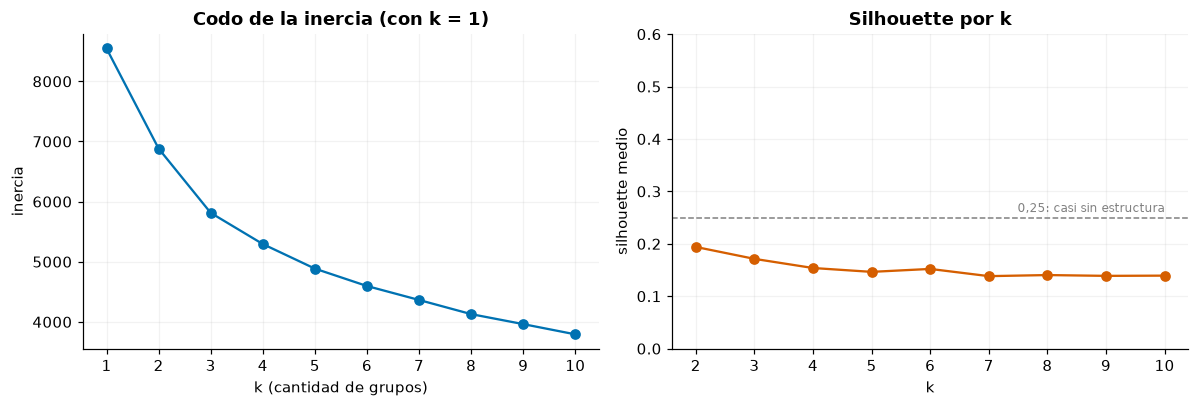

El silhouette elige **k = 2** (valor 0.194). Pero la inercia dice otra cosa: de 1 a 2 cae 1,665, de 2 a 3 cae 1,069 y de 3 a 4 cae 519: el último tramo grande es el que lleva a 3 grupos, y desde ahí la curva se aplana sin un codo marcado. **La medida y el codo no dicen lo mismo**, y los dos están lejos de 0,5: ningún *k* da grupos separados. Antes de decidir conviene mirar la estabilidad.

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].plot(barrido["k"], barrido["inercia"], "o-", color="#0072B2")
ejes[0].set(xlabel="k (cantidad de grupos)", ylabel="inercia", title="Codo de la inercia (con k = 1)", xticks=range(1, 11))
con_sil = barrido.dropna()
ejes[1].plot(con_sil["k"], con_sil["silhouette"], "o-", color="#D55E00")
ejes[1].axhline(0.25, color="gray", ls="--", lw=1)
ejes[1].text(10, 0.255, "0,25: casi sin estructura", ha="right", va="bottom", fontsize=8, color="gray")
ejes[1].set(xlabel="k", ylabel="silhouette medio", title="Silhouette por k", xticks=range(2, 11), ylim=(0, 0.6))
plt.tight_layout(); plt.show()

caida = barrido["inercia"].diff().abs().rename("caída de inercia respecto de k − 1")
texto(f"El silhouette elige **k = {automatico['agrupar'].k_}** (valor {con_sil['silhouette'].max():.3f}). "
      f"Pero la inercia dice otra cosa: de 1 a 2 cae {caida.iloc[1]:,.0f}, de 2 a 3 cae {caida.iloc[2]:,.0f} y de 3 a 4 "
      f"cae {caida.iloc[3]:,.0f}: el último tramo grande es el que lleva a 3 grupos, y desde ahí la curva "
      "se aplana sin un codo marcado. **La medida y el codo no dicen lo mismo**, y los dos están lejos de 0,5: "
      "ningún *k* da grupos separados. Antes de decidir conviene mirar la estabilidad.")

### 2.1 Estabilidad: ¿el corte se repite si cambian los datos?

Un silhouette bajo no dice si el corte es *arbitrario* o simplemente *suave*. Una segunda medida interna es la
**estabilidad**: se reajusta el pipeline completo (escalado incluido) sobre 30 remuestreos con reemplazo y se
compara cada corte con el original con el **índice de Rand ajustado** (ARI: 1 = mismos grupos, 0 = azar).

In [9]:
def estabilidad(ks, repeticiones=30):
    """ARI medio entre el corte con todos los perfiles y el de pipelines reajustados sobre remuestreos."""
    rng = np.random.default_rng(SEMILLA)
    filas = []
    for k in ks:
        base = Pipeline([("distancia", distancia()), ("agrupar", KMeans(k, n_init=10, random_state=SEMILLA))]).fit(X)
        referencia = base.predict(X)
        aris = []
        for _ in range(repeticiones):
            idx = rng.choice(len(X), len(X), replace=True)
            ajustado = clone(base).fit(X.iloc[idx])
            aris.append(adjusted_rand_score(referencia, ajustado.predict(X)))
        filas.append({"k": k, "ARI medio": np.mean(aris), "desvío": np.std(aris)})
    return pd.DataFrame(filas).set_index("k")


est = estabilidad(range(2, 8))
tabla_k = con_sil.set_index("k")[["silhouette"]].join(est).loc[2:7]
tamano_min = {}
for k in range(2, 8):
    etiquetas = KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(Z)
    tamano_min[k] = pd.Series(etiquetas).value_counts(normalize=True).min()
tabla_k["grupo más chico"] = pd.Series(tamano_min)
tabla_k

,silhouette,ARI medio,desvío,grupo más chico
k,,,,
2,0.194,0.876,0.062,0.360
3,0.171,0.866,0.073,0.266
4,0.154,0.675,0.162,0.173
5,0.146,0.628,0.155,0.118
6,0.152,0.590,0.149,0.065
7,0.138,0.495,0.078,0.067


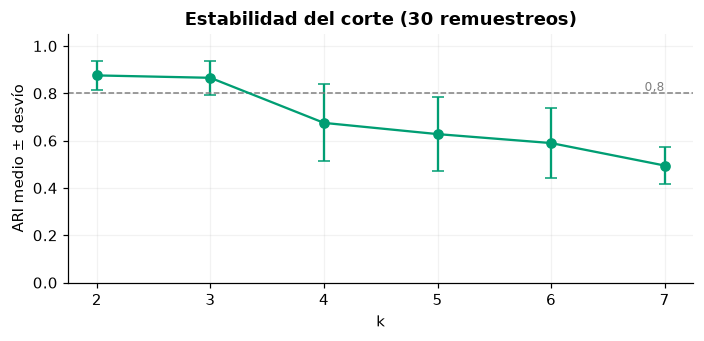

Con 2 y 3 grupos el corte se repite casi igual al cambiar los datos (ARI 0.88 y 0.87); desde 4 grupos cae a 0.68 y sigue bajando: los grupos de más de tres ya no son una propiedad de los datos, son el azar del remuestreo.

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.errorbar(tabla_k.index, tabla_k["ARI medio"], yerr=tabla_k["desvío"], fmt="o-", capsize=4, color="#009E73")
ax.axhline(0.8, color="gray", ls="--", lw=1); ax.text(7, 0.81, "0,8", ha="right", fontsize=8, color="gray")
ax.set(xlabel="k", ylabel="ARI medio ± desvío", title="Estabilidad del corte (30 remuestreos)", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

s2, s3, s4 = (tabla_k.loc[k, "silhouette"] for k in (2, 3, 4))
a2, a3, a4 = (tabla_k.loc[k, "ARI medio"] for k in (2, 3, 4))
texto(f"Con 2 y 3 grupos el corte se repite casi igual al cambiar los datos (ARI {a2:.2f} y {a3:.2f}); desde 4 grupos cae a "
      f"{a4:.2f} y sigue bajando: los grupos de más de tres ya no son una propiedad de los datos, son el azar del remuestreo.")

### 2.2 La decisión: k = 3, declarada

Reglas puestas antes de mirar los grupos, para no elegir por el resultado que más guste:

1. **El silhouette elige 2**, y esa es la respuesta de la medida. Con 2 grupos el corte es estable, pero separa
   solo "sacadores contra el resto": un único eje.
2. **El codo marca 3**: es el último tramo donde agregar un grupo mejora mucho la inercia.
3. **La estabilidad se mantiene en 3** igual que en 2 (ARI cerca de 0,87) y cae claramente en 4.
4. La diferencia de silhouette entre 2 y 3 es de unas dos centésimas, mucho menos que la distancia a 0,5.

Entonces **se elige k = 3**, y se declara como una decisión del grupo y no del silhouette: es el *k* más grande
que sigue siendo estable, el que marca el codo, y el que se puede describir con una columna cada grupo (Parte 3). La
elección de 2 queda como la lectura más conservadora. La de 4 o 5 se descarta: no es estable. La de 5 grupos
que sugería la intuición de tenis (sacador, restador, completo, defensivo, irregular) **no aparece** en los datos
(Parte 6).

In [11]:
K = 3
pipeline = Pipeline([("distancia", distancia()),
                     ("agrupar", KMeans(n_clusters=K, n_init=10, random_state=SEMILLA))]).fit(X)

Z = pipeline[:-1].transform(X)           # lo que llega al último paso: las siete columnas estandarizadas
etiqueta_cruda = pipeline.predict(X)
texto(f"Pipeline final: `EstandarizarPorGrupo` → `KMeans(n_clusters={K}, random_state={SEMILLA})`. "
      f"Silhouette: **{silhouette_score(Z, etiqueta_cruda):.3f}**; inercia {pipeline['agrupar'].inertia_:,.0f}.")

Pipeline final: `EstandarizarPorGrupo` → `KMeans(n_clusters=3, random_state=42)`. Silhouette: **0.171**; inercia 5,813.

## Parte 3 — Los grupos

K-means numera los grupos en cualquier orden, y el orden puede cambiar entre máquinas. Para que los nombres
no dependan de eso, se nombra cada grupo **por su perfil** y no por su número:

- el de **mayor `tasa_aces`** es el de los sacadores de potencia;
- de los otros dos, el de **menor `efectividad_segundo`** es el del saque frágil;
- el que queda, el de los restadores sólidos.

In [12]:
centros_z = pd.DataFrame(pipeline["agrupar"].cluster_centers_, columns=COLUMNAS)


def nombrar(centros):
    """Nombre de cada grupo según su columna más distintiva, no según el número que le tocó."""
    assert len(centros) == 3
    sacadores = centros["tasa_aces"].idxmax()
    resto = [i for i in centros.index if i != sacadores]
    fragil = centros.loc[resto, "efectividad_segundo"].idxmin()
    regular = next(i for i in resto if i != fragil)
    return {sacadores: "Sacadores de potencia", fragil: "Saque frágil", regular: "Restadores sólidos"}


NOMBRES = nombrar(centros_z)
ORDEN_NOMBRES = ["Sacadores de potencia", "Restadores sólidos", "Saque frágil"]
X["estilo"] = pd.Series(etiqueta_cruda, index=X.index).map(NOMBRES)
X["estilo"] = pd.Categorical(X["estilo"], categories=ORDEN_NOMBRES, ordered=True)
Z["estilo"] = X["estilo"]

tamano = X["estilo"].value_counts().reindex(ORDEN_NOMBRES)
perfil = X.groupby("estilo", observed=True)[COLUMNAS].mean().reindex(ORDEN_NOMBRES) * 100
perfil.insert(0, "perfiles", tamano)
perfil.insert(1, "% del total", tamano / tamano.sum() * 100)
display(perfil.rename(columns=ETIQUETAS).round(1))

,perfiles,% del total,aces,dobles faltas,1.er saque dentro,2.º saque ganado,BP salvados,puntos al resto,BP convertidos
estilo,,,,,,,,,
Sacadores de potencia,326,26.600,10.800,4.100,60.900,50.800,63.400,33.900,35.400
Restadores sólidos,496,40.500,5.900,3.100,62.600,51.400,60.800,37.700,40.200
Saque frágil,402,32.800,6.100,4.500,58.800,48.200,57.800,36.500,39.000


La tabla está en **unidades originales** (porcentajes de puntos). Para ver *qué distingue* a cada grupo conviene
la versión estandarizada: cuántos desvíos por encima o por debajo del promedio de su superficie está cada grupo
en cada columna.

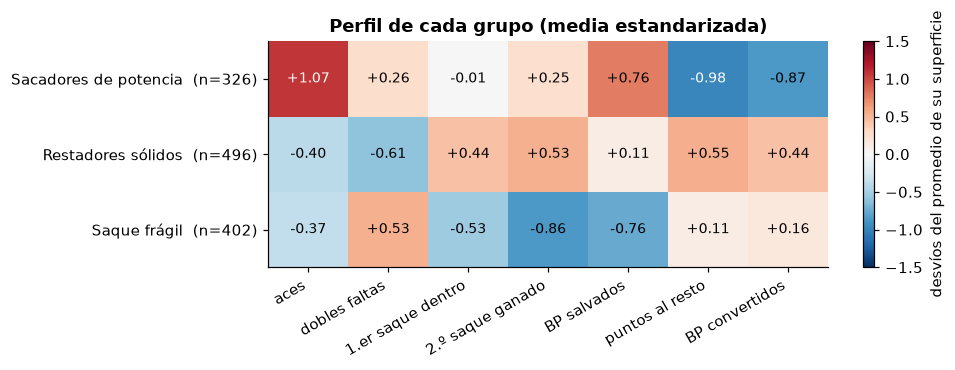

In [13]:
z_centros = Z.groupby("estilo", observed=True)[COLUMNAS].mean().reindex(ORDEN_NOMBRES)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(z_centros, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(COLUMNAS)), [ETIQUETAS[c] for c in COLUMNAS], rotation=30, ha="right")
ax.set_yticks(range(3), [f"{n}  (n={tamano[n]})" for n in ORDEN_NOMBRES])
for i in range(3):
    for j in range(len(COLUMNAS)):
        ax.text(j, i, f"{z_centros.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(z_centros.iloc[i, j]) > .9 else "black")
ax.grid(False); fig.colorbar(im, label="desvíos del promedio de su superficie")
ax.set_title("Perfil de cada grupo (media estandarizada)")
plt.tight_layout(); plt.show()

In [14]:
def eta2(x, g):
    """Fracción de la varianza de la columna que explican los grupos (0 = no distinguen, 1 = distinguen todo)."""
    v = pd.DataFrame({"x": x, "g": g}).dropna()
    gr = v.groupby("g", observed=True)["x"]
    total = ((v["x"] - v["x"].mean()) ** 2).sum()
    return (gr.count() * (gr.mean() - v["x"].mean()) ** 2).sum() / total


distingue = pd.Series({ETIQUETAS[c]: eta2(Z[c], Z["estilo"]) for c in COLUMNAS}, name="η² (varianza explicada por los grupos)")
distingue = distingue.sort_values(ascending=False)
display(distingue.to_frame().round(3))

mas = distingue.index[0]; menos = distingue.index[-1]
texto(f"**Qué distingue a un grupo de otro:** la columna que más separa los tres grupos es *{mas}* "
      f"(η² = {distingue.iloc[0]:.2f}) y la que menos, *{menos}* (η² = {distingue.iloc[-1]:.2f}). "
      "Las columnas de devolución, aces y segundo saque llevan la mayor parte de la diferencia.")

,η² (varianza explicada por los grupos)
aces,0.415
puntos al resto,0.381
2.º saque ganado,0.372
BP salvados,0.352
BP convertidos,0.287
dobles faltas,0.262
1.er saque dentro,0.171


**Qué distingue a un grupo de otro:** la columna que más separa los tres grupos es *aces* (η² = 0.41) y la que menos, *1.er saque dentro* (η² = 0.17). Las columnas de devolución, aces y segundo saque llevan la mayor parte de la diferencia.

In [15]:
# El nombre se defiende con una columna: se verifica que cada grupo sea extremo en la que lo nombra
assert z_centros.loc["Sacadores de potencia", "tasa_aces"] == z_centros["tasa_aces"].max()
assert z_centros.loc["Saque frágil", "efectividad_segundo"] == z_centros["efectividad_segundo"].min()
assert z_centros.loc["Restadores sólidos", "puntos_ganados_resto"] == z_centros["puntos_ganados_resto"].max()

# Los nombres defendidos con una columna y con jugadores que cualquiera reconoce
ejemplos = {}
for n in ORDEN_NOMBRES:
    sub = X[X["estilo"] == n].sort_values("partidos", ascending=False)
    ejemplos[n] = ", ".join(sub["nombre"].drop_duplicates().head(8))
for n in ORDEN_NOMBRES:
    columna = {"Sacadores de potencia": "tasa_aces", "Restadores sólidos": "puntos_ganados_resto",
               "Saque frágil": "efectividad_segundo"}[n]
    texto(f"**{n}** — columna que lo nombra: `{columna}` ({z_centros.loc[n, columna]:+.2f} desvíos). "
          f"Más partidos jugados: {ejemplos[n]}.")

**Sacadores de potencia** — columna que lo nombra: `tasa_aces` (+1.07 desvíos). Más partidos jugados: Marin Cilic, John Isner, Andy Roddick, Feliciano Lopez, Jo-Wilfried Tsonga, Sam Querrey, Ivo Karlovic, Nicolas Almagro.

**Restadores sólidos** — columna que lo nombra: `puntos_ganados_resto` (+0.55 desvíos). Más partidos jugados: Roger Federer, Novak Djokovic, Andy Murray, Rafael Nadal, Tomas Berdych, Richard Gasquet, Gael Monfils, Stan Wawrinka.

**Saque frágil** — columna que lo nombra: `efectividad_segundo` (-0.86 desvíos). Más partidos jugados: Marcos Baghdatis, Fabio Fognini, David Goffin, Viktor Troicki, Julien Benneteau, Guillermo Garcia-Lopez, Benoit Paire, Yen-Hsun Lu.

### 3.1 Cómo se leen los tres estilos

- **Sacadores de potencia.** Aces muy por encima del promedio de la superficie, salvan muchos break points al
  sacar, y pagan el precio en la devolución: ganan menos puntos al resto y convierten menos quiebres. Es el
  compromiso que H5 de la Entrega 2 midió en r ≈ −0,58, convertido en un grupo.
- **Restadores sólidos.** La mejor devolución (ganan más puntos al resto y convierten más break points), con
  pocas dobles faltas y buen segundo saque. Pocos aces: ganan devolviendo y sin regalar puntos al sacar.
- **Saque frágil.** El segundo saque rinde mal, más dobles faltas y menos primeros saques dentro, y en consecuencia
  salvan menos break points: el saque es su punto débil, y la devolución queda alrededor del promedio.

Los tres nombres se verificaron con una columna y con jugadores reconocibles, **pero siguen siendo cortes**: se
mira a continuación si los grupos están realmente separados.

### 3.2 Para mirar, no para formar: superficie y resultados

Ni la superficie ni las victorias formaron los grupos. Se las cruza ahora, solo para describir.

In [16]:
# Qué fracción de cada superficie cae en cada estilo (las columnas suman 100 %)
display((pd.crosstab(X["estilo"], X["superficie"], normalize="columns") * 100).round(1))

resultados = X.groupby("estilo", observed=True).agg(
    perfiles=("id", "size"), partidos_medios=("partidos", "mean"), winrate_medio=("winrate", "mean"),
    titulos_por_perfil=("titulos", "mean")).reindex(ORDEN_NOMBRES)
display(resultados.round(3))

superficie,cemento,clay,grass
estilo,,,
Sacadores de potencia,27.000,25.700,27.400
Restadores sólidos,39.700,43.200,37.500
Saque frágil,33.300,31.000,35.100


,perfiles,partidos_medios,winrate_medio,titulos_por_perfil
estilo,,,,
Sacadores de potencia,326,93.206,0.456,0.997
Restadores sólidos,496,144.649,0.521,2.349
Saque frágil,402,72.097,0.393,0.234


In [17]:
# ¿cambia un jugador de estilo cuando cambia de superficie? Solo jugadores con 2 o más perfiles confiables
multi = X.groupby("id").filter(lambda g: len(g) >= 2)
cambia = multi.groupby("id")["estilo"].nunique().gt(1)
por_par = []
for a, b in [("cemento", "clay"), ("cemento", "grass"), ("clay", "grass")]:
    ambos = X[X["superficie"].isin([a, b])].pivot(index="id", columns="superficie", values="estilo").dropna()
    por_par.append({"par": f"{a} – {b}", "jugadores": len(ambos), "mismo estilo": (ambos[a] == ambos[b]).mean()})
display(pd.DataFrame(por_par).set_index("par").round(3))
texto(f"De {len(cambia):,} jugadores con al menos dos superficies confiables, **{cambia.mean():.0%} cambia de estilo "
      "según la superficie**. El estilo no es un rasgo fijo de la persona: depende de dónde juega.")

,jugadores,mismo estilo
par,,
cemento – clay,391,0.678
cemento – grass,251,0.693
clay – grass,221,0.638


De 421 jugadores con al menos dos superficies confiables, **42% cambia de estilo según la superficie**. El estilo no es un rasgo fijo de la persona: depende de dónde juega.

In [18]:
r = resultados["winrate_medio"]
texto(f"**Para mirar (no para concluir):** el winrate medio es {r['Restadores sólidos']:.1%} en los restadores sólidos, "
      f"{r['Sacadores de potencia']:.1%} en los sacadores de potencia y {r['Saque frágil']:.1%} en el saque frágil. "
      "Hay un orden, pero hay que leerlo con cautela por dos motivos: (1) se filtró por ≥ 20 partidos, así que "
      "los que juegan mucho son los que ganan; (2) `bp_salvados`, `efectividad_segundo` y `puntos_ganados_resto` ya son "
      "en parte *consecuencia* de ganar. Es una descripción, no una prueba de que un estilo sea superior.")

**Para mirar (no para concluir):** el winrate medio es 52.1% en los restadores sólidos, 45.6% en los sacadores de potencia y 39.3% en el saque frágil. Hay un orden, pero hay que leerlo con cautela por dos motivos: (1) se filtró por ≥ 20 partidos, así que los que juegan mucho son los que ganan; (2) `bp_salvados`, `efectividad_segundo` y `puntos_ganados_resto` ya son en parte *consecuencia* de ganar. Es una descripción, no una prueba de que un estilo sea superior.

In [ ]:
# Tipo de revés por estilo: variable para MIRAR los grupos, no entró a la distancia (validación externa)
REVES = {"2H": "Dos manos", "1H": "Una mano"}
CATEGORIAS = ["Dos manos", "Una mano", "No especificado"]
reves = (X[["id", "estilo"]]
         .merge(df[["id-jugador", "tipo-reves"]], left_on="id", right_on="id-jugador", how="left")["tipo-reves"]
         .map(REVES).fillna("No especificado"))

cantidad = pd.crosstab(X["estilo"], reves, margins=True, margins_name="Total")[CATEGORIAS + ["Total"]]
porcentaje = cantidad[CATEGORIAS].div(cantidad["Total"], axis=0) * 100

tabla_reves = pd.DataFrame(index=cantidad.index)
for c in CATEGORIAS:
    tabla_reves[c] = cantidad[c].astype(str) + " (" + porcentaje[c].round(1).astype(str) + "%)"
tabla_reves["Total"] = cantidad["Total"]
# % de una mano solo entre los perfiles con revés conocido, para comparar grupos sin que pesen los faltantes
tabla_reves["% una mano (sobre conocidos)"] = (cantidad["Una mano"] / cantidad[["Dos manos", "Una mano"]].sum(axis=1) * 100).round(1)
display(tabla_reves)

texto(f"**Tipo de revés por estilo** (contado por perfil jugador–superficie; los porcentajes entre paréntesis son por fila). "
      f"El revés falta en {cantidad.loc['Total', 'No especificado']} de {cantidad.loc['Total', 'Total']} perfiles. "
      f"Entre los que lo tienen, el revés a una mano es del "
      f"{tabla_reves.loc['Sacadores de potencia', '% una mano (sobre conocidos)']:.0f}% en los sacadores, "
      f"{tabla_reves.loc['Restadores sólidos', '% una mano (sobre conocidos)']:.0f}% en los restadores y "
      f"{tabla_reves.loc['Saque frágil', '% una mano (sobre conocidos)']:.0f}% en el saque frágil. "
      "Es una validación externa: el revés no entró a la distancia y aun así se reparte distinto entre los grupos.")

,Dos manos,Una mano,No especificado,Total,% una mano (sobre conocidos)
estilo,,,,,
Sacadores de potencia,207 (63.5%),91 (27.9%),28 (8.6%),326,30.500
Restadores sólidos,356 (71.8%),95 (19.2%),45 (9.1%),496,21.100
Saque frágil,263 (65.4%),56 (13.9%),83 (20.6%),402,17.600
Total,826 (67.5%),242 (19.8%),156 (12.7%),1224,22.700


**Tipo de revés por estilo** (contado por perfil jugador–superficie; los porcentajes entre paréntesis son por fila). El revés falta en 156 de 1224 perfiles. Entre los que lo tienen, el revés a una mano es del 30% en los sacadores, 21% en los restadores y 18% en el saque frágil. Es una validación externa: el revés no entró a la distancia y aun así se reparte distinto entre los grupos.

## Parte 4 — Una proyección para mirar

Siete columnas no se pueden dibujar. **PCA** busca las direcciones en las que los perfiles más se diferencian.
Se ajusta sobre los datos ya estandarizados (el pipeline sin su último paso) y solo se usa para *mirar*:
**el agrupamiento se hizo en las siete dimensiones, no en estas dos**.

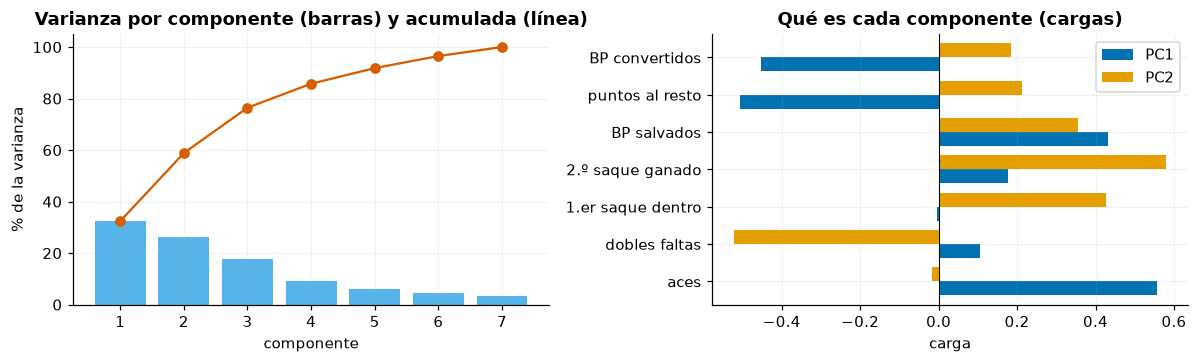

La primera componente se queda con el **32%** de la varianza y la segunda con el 26%: dos direcciones explican el 59% y con cuatro se llega al 86%. Esto es mucho más repartido que en la Práctica 3 (donde una componente se llevaba el 59 %): acá no hay una dirección que lo explique todo.

In [19]:
pca = Pipeline([("distancia", distancia()), ("pca", PCA(random_state=SEMILLA))]).fit(X)
componentes = pca["pca"]
var = componentes.explained_variance_ratio_

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
ejes[0].bar(range(1, 8), var * 100, color="#56B4E9")
ejes[0].plot(range(1, 8), np.cumsum(var) * 100, "o-", color="#D55E00")
ejes[0].set(xlabel="componente", ylabel="% de la varianza", title="Varianza por componente (barras) y acumulada (línea)")
cargas = pd.DataFrame(componentes.components_[:2].T, index=[ETIQUETAS[c] for c in COLUMNAS], columns=["PC1", "PC2"])
cargas.plot(kind="barh", ax=ejes[1], color=["#0072B2", "#E69F00"], width=.75)
ejes[1].axvline(0, color="black", lw=.7); ejes[1].set(title="Qué es cada componente (cargas)", xlabel="carga")
plt.tight_layout(); plt.show()
texto(f"La primera componente se queda con el **{var[0]:.0%}** de la varianza y la segunda con el {var[1]:.0%}: dos direcciones "
      f"explican el {var[:2].sum():.0%} y con cuatro se llega al {np.cumsum(var)[3]:.0%}. Esto es mucho más "
      "repartido que en la Práctica 3 (donde una componente se llevaba el 59 %): acá no hay una dirección que lo explique todo.")

**PC1** opone aces, BP salvados (carga positiva) a puntos al resto, BP convertidos (negativa): es el **eje saque potente contra devolución**. **PC2** opone 2.º saque ganado, 1.er saque dentro, BP salvados a dobles faltas: es el **eje de regularidad del saque**. (Solo se nombran cargas mayores a 0,3 en valor absoluto.)

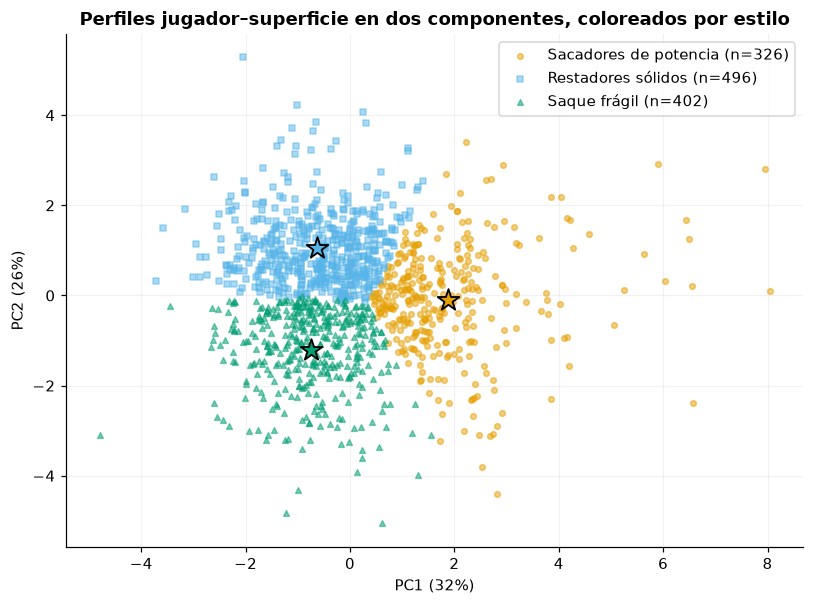

In [20]:
def polos(carga, umbral=0.3):
    """Columnas con carga importante (|carga| > umbral), separadas por signo."""
    pos = carga[carga > umbral].sort_values(ascending=False).index
    neg = carga[carga < -umbral].sort_values().index
    return ", ".join(pos), ", ".join(neg)


p1, n1 = polos(cargas["PC1"]); p2, n2 = polos(cargas["PC2"])
texto(f"**PC1** opone {p1} (carga positiva) a {n1} (negativa): es el **eje saque potente contra devolución**. "
      f"**PC2** opone {p2} a {n2}: es el **eje de regularidad del saque**. (Solo se nombran cargas mayores a 0,3 en valor absoluto.)")

proy = pd.DataFrame(pca.transform(X)[:, :2], columns=["PC1", "PC2"], index=X.index)
fig, ax = plt.subplots(figsize=(7.5, 5.6))
for n, color, marca in zip(ORDEN_NOMBRES, OKABE_ITO[:3], MARCADORES):
    p = proy[X["estilo"] == n]
    ax.scatter(p["PC1"], p["PC2"], s=14, alpha=.5, color=color, marker=marca, label=f"{n} (n={len(p)})")
    ax.scatter(*p.mean(), s=220, marker="*", color=color, edgecolor="black", lw=1.2, zorder=5)
ax.set(xlabel=f"PC1 ({var[0]:.0%})", ylabel=f"PC2 ({var[1]:.0%})",
       title="Perfiles jugador–superficie en dos componentes, coloreados por estilo")
ax.legend(); plt.tight_layout(); plt.show()

El gráfico responde la pregunta de fondo: los tres colores **ocupan regiones distintas del plano pero se tocan y se
pisan en los bordes**; no hay huecos entre ellos. Son **cortes de un degradé**, no islas. Las siluetas lo
confirman: cada perfil tiene un valor `s(i)` y, si los grupos estuvieran separados, casi todos estarían cerca
de 1; si son cortes de una nube continua, la mayoría queda bajo 0,3 y algunos pasan a negativo (están más cerca
del centro de otro grupo que del suyo).

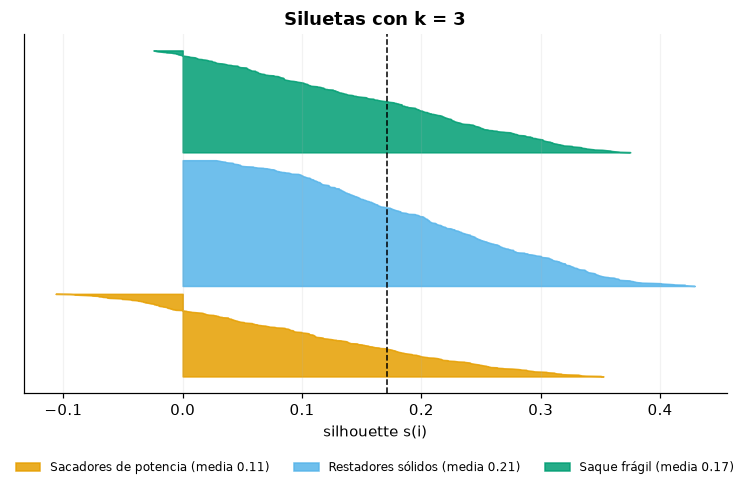

Silhouette medio 0.171. El 73% de los perfiles tiene `s(i)` por debajo de 0,25 y el 7% es negativo: están en la frontera.

In [21]:
def graficar_siluetas(Zm, etiquetas, nombres, titulo):
    """Gráfico de Rousseeuw: cada perfil es una línea de largo s(i); un grupo debajo del otro, ordenados."""
    s = silhouette_samples(Zm, etiquetas)
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    y0 = 0
    for color, n in zip(OKABE_ITO, nombres):
        v = np.sort(s[etiquetas == n])[::-1]
        ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=color, alpha=.85, label=f"{n} (media {v.mean():.2f})")
        y0 += len(v) + 30
    ax.axvline(s.mean(), color="black", ls="--", lw=1)
    ax.set(xlabel="silhouette s(i)", yticks=[], title=titulo); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=8, frameon=False)
    plt.tight_layout(); plt.show()
    return s


s_i = graficar_siluetas(Z[COLUMNAS], X["estilo"].to_numpy(), ORDEN_NOMBRES, f"Siluetas con k = {K}")
negativos = (s_i < 0).mean(); bajos = (s_i < 0.25).mean()
texto(f"Silhouette medio {s_i.mean():.3f}. El {bajos:.0%} de los perfiles tiene `s(i)` por debajo de 0,25 y el "
      f"{negativos:.0%} es negativo: están en la frontera.")

### 4.1 La otra definición de grupo: DBSCAN

K-means siempre corta, haya grupos o no. Para saber si hay *huecos* que cortar se usa la otra definición de la
Práctica 3: **DBSCAN** llama grupo a una zona densa separada de otras por zonas vacías, y deja como **ruido** (`−1`)
lo que no tiene vecinos cerca. No hay que decirle cuántos grupos hay: si los datos tuvieran islas, las encontraría.
`min_samples = 10` y se barre `eps`.

,grupos,perfiles en el grupo mayor,ruido,% ruido
eps,,,,
0.800,4,16,1174,95.900
1.000,2,452,763,62.300
1.200,1,817,407,33.300
1.500,1,1065,159,13.000
2.000,1,1190,34,2.800
2.500,1,1218,6,0.500


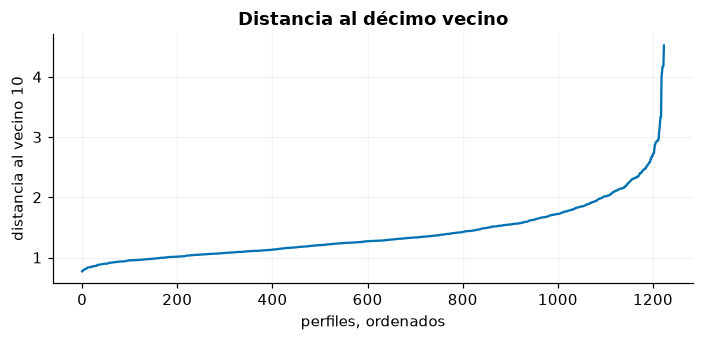

In [22]:
from sklearn.neighbors import NearestNeighbors

MIN_VECINOS = 10
Zm = Z[COLUMNAS].to_numpy()
dist10 = np.sort(NearestNeighbors(n_neighbors=MIN_VECINOS).fit(Zm).kneighbors(Zm)[0][:, -1])

filas = []
for eps in [0.8, 1.0, 1.2, 1.5, 2.0, 2.5]:
    lab = DBSCAN(eps=eps, min_samples=MIN_VECINOS).fit_predict(Zm)
    grupos = pd.Series(lab[lab >= 0]).value_counts()
    filas.append({"eps": eps, "grupos": len(grupos), "perfiles en el grupo mayor": int(grupos.max()) if len(grupos) else 0,
                  "ruido": int((lab == -1).sum()), "% ruido": (lab == -1).mean() * 100})
barrido_eps = pd.DataFrame(filas).set_index("eps")
display(barrido_eps.round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(dist10, color="#0072B2"); ax.set(xlabel="perfiles, ordenados", ylabel=f"distancia al vecino {MIN_VECINOS}", title="Distancia al décimo vecino")
plt.tight_layout(); plt.show()

In [23]:
texto(f"Con `eps` chico (0,8) la nube se desarma en {int(barrido_eps.loc[0.8, 'grupos'])} pedacitos y el "
      f"{barrido_eps.loc[0.8, '% ruido']:.0f}% queda como ruido; a partir de `eps` = 1,2 aparece **un solo grupo** que va "
      f"absorbiendo el ruido hasta quedar con {int(barrido_eps.loc[2.5, 'perfiles en el grupo mayor']):,} de {len(X):,} perfiles. "
      "No hay ningún `eps` que devuelva dos o tres grupos de tamaño parecido: **no hay huecos**. "
      "DBSCAN dice lo mismo que las siluetas: la nube de perfiles es continua y los tres estilos son cortes de ella.")

Con `eps` chico (0,8) la nube se desarma en 4 pedacitos y el 96% queda como ruido; a partir de `eps` = 1,2 aparece **un solo grupo** que va absorbiendo el ruido hasta quedar con 1,218 de 1,224 perfiles. No hay ningún `eps` que devuelva dos o tres grupos de tamaño parecido: **no hay huecos**. DBSCAN dice lo mismo que las siluetas: la nube de perfiles es continua y los tres estilos son cortes de ella.

## Parte 5 — Lo que domina

Dos preguntas por separado: si **un grupo se lleva todo**, y si **una columna corta sola**.

**Un grupo.** Los tres tienen entre el 27 % y el 41 % de los perfiles (tabla de la Parte 3): ninguno se lleva todo
ni queda vacío. Si el tamaño de un grupo hubiera sido del 90 %, habría que haber mirado antes la escala.

**Una columna.** Se prueba cada opción reajustando el *pipeline completo* con una columna menos y comparando con
el agrupamiento original mediante el ARI. Si sacar una columna casi no cambia nada (ARI cerca de 1), esa columna
no estaba decidiendo; si cambia mucho, estaba cortando sola o sosteniendo el corte.

In [24]:
def con_columnas(columnas, centrar=True, k=K):
    p = Pipeline([("distancia", distancia(columnas, centrar)), ("agrupar", KMeans(k, n_init=10, random_state=SEMILLA))]).fit(X)
    return p, p.predict(X), p[:-1].transform(X)


filas = [{"variante": "las siete (decisión)", "silhouette": silhouette_score(Z[COLUMNAS], etiqueta_cruda), "ARI vs. las siete": 1.0}]
for c in COLUMNAS:
    cols = [x for x in COLUMNAS if x != c]
    _, lab, Zv = con_columnas(cols)
    filas.append({"variante": f"sin {ETIQUETAS[c]}", "silhouette": silhouette_score(Zv, lab),
                  "ARI vs. las siete": adjusted_rand_score(etiqueta_cruda, lab)})

cols = [x for x in COLUMNAS if x not in ("puntos_ganados_resto", "bp_convertidos")]
_, lab, Zv = con_columnas(cols)
filas.append({"variante": "sin las dos de devolución", "silhouette": silhouette_score(Zv, lab),
              "ARI vs. las siete": adjusted_rand_score(etiqueta_cruda, lab)})

_, lab_crudo, Zc = con_columnas(COLUMNAS, centrar=False)
filas.append({"variante": "sin escalar (columnas crudas)", "silhouette": np.nan,
              "ARI vs. las siete": adjusted_rand_score(etiqueta_cruda, lab_crudo)})
_, lab8, Z8 = con_columnas(COLUMNAS + ["efectividad_primero"])
filas.append({"variante": "con la redundante (1.er saque ganado)", "silhouette": silhouette_score(Z8, lab8),
              "ARI vs. las siete": adjusted_rand_score(etiqueta_cruda, lab8)})
comparacion = pd.DataFrame(filas).set_index("variante")
comparacion

,silhouette,ARI vs. las siete
variante,,
las siete (decisión),0.171,1.000
sin aces,0.178,0.633
sin dobles faltas,0.178,0.663
sin 1.er saque dentro,0.192,0.746
sin 2.º saque ganado,0.174,0.577
sin BP salvados,0.183,0.701
sin puntos al resto,0.176,0.718
sin BP convertidos,0.187,0.782
sin las dos de devolución,0.210,0.392


In [25]:
una_menos = [v for v in comparacion.index if v.startswith("sin ") and "escalar" not in v and "dos de" not in v]
sin = comparacion.loc[una_menos, "ARI vs. las siete"]
ari_dos = comparacion.loc["sin las dos de devolución", "ARI vs. las siete"]
mas_pesa, menos_pesa = sin.idxmin(), sin.idxmax()
participacion = (X[COLUMNAS].var() / X[COLUMNAS].var().sum()).sort_values(ascending=False)
texto(f"**Qué pasaría si sacaras una columna.** Ninguna decide sola: al sacar cualquiera, el ARI contra el corte original queda entre "
      f"{sin.min():.2f} y {sin.max():.2f}. Sacar *{mas_pesa.replace('sin ', '')}* es lo que más cambia los grupos (ARI {sin.min():.2f}) y "
      f"sacar *{menos_pesa.replace('sin ', '')}* es lo que menos (ARI {sin.max():.2f}). Las dos columnas de devolución pesan menos por separado "
      f"porque se solapan entre sí (r = {r2:.2f}); sacadas las dos juntas el ARI es {ari_dos:.2f}.\n\n"
      f"**Sin escalar** los grupos casi no se parecen a los del pipeline (ARI {comparacion.loc['sin escalar (columnas crudas)', 'ARI vs. las siete']:.2f}): "
      f"con las columnas crudas, `{ETIQUETAS[participacion.index[0]]}` aporta el {participacion.iloc[0]:.0%} de la varianza total y "
      f"`{ETIQUETAS[participacion.index[-1]]}` solo el {participacion.iloc[-1]:.0%}, y la distancia terminaría decidida por "
      "las columnas de mayor varianza. Escalar por superficie es lo que hace que cada columna pese lo mismo.\n\n"
      f"**Con la redundante** (`efectividad_primero`) los grupos cambian poco (ARI {comparacion.loc['con la redundante (1.er saque ganado)', 'ARI vs. las siete']:.2f}) "
      "pero el saque potente pasa a pesar doble, que es la razón por la que sale.")

**Qué pasaría si sacaras una columna.** Ninguna decide sola: al sacar cualquiera, el ARI contra el corte original queda entre 0.58 y 0.78. Sacar *2.º saque ganado* es lo que más cambia los grupos (ARI 0.58) y sacar *BP convertidos* es lo que menos (ARI 0.78). Las dos columnas de devolución pesan menos por separado porque se solapan entre sí (r = 0.65); sacadas las dos juntas el ARI es 0.39.

**Sin escalar** los grupos casi no se parecen a los del pipeline (ARI 0.25): con las columnas crudas, `BP salvados` aporta el 22% de la varianza total y `dobles faltas` solo el 2%, y la distancia terminaría decidida por las columnas de mayor varianza. Escalar por superficie es lo que hace que cada columna pese lo mismo.

**Con la redundante** (`efectividad_primero`) los grupos cambian poco (ARI 0.74) pero el saque potente pasa a pesar doble, que es la razón por la que sale.

In [26]:
mayor_carga = cargas.abs().max(axis=1).sort_values(ascending=False)
carga_pc1 = cargas["PC1"].abs().sort_values(ascending=False)
texto(f"**Decisión sobre lo que domina.** No hay una columna que corte sola: la carga más alta en PC1 es de *{carga_pc1.index[0]}* "
      f"({carga_pc1.iloc[0]:.2f}), ninguna se acerca a 1, y la varianza se reparte en varias direcciones. Lo que sí domina es un **eje**: "
      "aces y break points salvados por un lado, y devolución por el otro, se mueven juntos (en sentidos opuestos) y definen PC1. "
      "Se decidió **conservar las siete columnas y no fusionarlas en un índice**: ninguna es copia de otra, sacar cualquiera "
      "cambia los grupos, y el eje sacador–restador es justamente lo que el proyecto quiere medir. "
      "Lo que cambió después de revisar esto: nada en el pipeline, pero la descripción de los grupos dice explícitamente "
      "que dos de ellos son los polos de ese eje y que el tercero se distingue por la regularidad del saque.")

**Decisión sobre lo que domina.** No hay una columna que corte sola: la carga más alta en PC1 es de *aces* (0.56), ninguna se acerca a 1, y la varianza se reparte en varias direcciones. Lo que sí domina es un **eje**: aces y break points salvados por un lado, y devolución por el otro, se mueven juntos (en sentidos opuestos) y definen PC1. Se decidió **conservar las siete columnas y no fusionarlas en un índice**: ninguna es copia de otra, sacar cualquiera cambia los grupos, y el eje sacador–restador es justamente lo que el proyecto quiere medir. Lo que cambió después de revisar esto: nada en el pipeline, pero la descripción de los grupos dice explícitamente que dos de ellos son los polos de ese eje y que el tercero se distingue por la regularidad del saque.

## Parte 6 — Lo que no apareció

Esto también es resultado. Lo que esperábamos al plantear la Entrega 2 y los datos no dieron:

1. **No hay grupos separados.** El silhouette más alto es de 0,19 (0,17 con los tres grupos finales) y está lejos
   de 0,5; las siluetas tienen perfiles negativos; DBSCAN no encuentra huecos. Los tres estilos son **cortes de un
   degradé**, útiles para describir, pero no "tipos de jugador que existían".
2. **No aparecen cinco o más estilos.** La intuición de tenis (sacador, restador, completo, defensivo, irregular,
   ofensivo) no se sostiene: con 4 grupos el corte ya es inestable (el ARI cae a unos 0,7 y sigue bajando). Con las siete
   tasas disponibles el dato soporta tres.
3. **No hay un estilo de "golpeo".** La fuente no trae derecha, revés ni spin: lo que llamamos estilo es solo
   **saque y devolución**. No se puede separar, por ejemplo, al defensivo de fondo del ofensivo agresivo.
4. **El estilo no es del jugador.** Una parte importante de los jugadores con dos superficies confiables cambia de
   estilo al cambiar de superficie (Parte 3.2); la superficie no define los grupos, pero el estilo sí depende de dónde se juega.
5. **El silhouette y el codo no coinciden.** El silhouette elige 2, el codo apunta a 3. Se eligió 3 por una regla
   declarada (estabilidad y descripción), y se dice acá.
6. **No se puede afirmar que un estilo sea superior.** El orden de winrate existe, pero está contaminado por
   el filtro de 20 partidos y por columnas que son consecuencia de ganar. Esa pregunta de la Entrega 2 queda
   para el modelo supervisado, con historial anterior al partido.

## Parte 7 — Salidas para la Entrega 4

La aplicación de la Entrega 4 necesita tres cosas: **el pipeline entrenado**, **la asignación de estilos por
perfil** y **los parámetros en texto plano** (para poder calcular en el navegador sin Python, como hace el HTML
de la práctica con la logística). Se guardan en `resultados/` y se verifica que el pipeline guardado devuelva lo
mismo al volver a cargarlo.

In [27]:
import joblib, sklearn

# 1) la asignación de cada perfil confiable
asignacion = X[["id", "nombre", "superficie", "partidos", "winrate", "estilo"]].copy()
asignacion = pd.concat([asignacion, Z[COLUMNAS].add_suffix("_z")], axis=1)
asignacion.to_csv(OUT / "estilos_jugador_superficie.csv", index=False, encoding="utf-8-sig")

# 2) el perfil de cada estilo, en unidades originales y estandarizadas
perfil_estilos = X.groupby("estilo", observed=True)[COLUMNAS].mean().reindex(ORDEN_NOMBRES)
perfil_estilos.assign(perfiles=tamano).to_csv(OUT / "estilos_perfil.csv", encoding="utf-8-sig")

# 3) el pipeline entrenado y sus parámetros en texto plano
joblib.dump({"pipeline": pipeline, "nombres": NOMBRES, "columnas": COLUMNAS}, OUT / "pipeline_estilos.joblib")
paso = pipeline["distancia"]
config = {
    "semilla": SEMILLA, "k": K, "columnas": COLUMNAS, "nombres_por_grupo": {str(k): v for k, v in NOMBRES.items()},
    "media_por_superficie": paso.media_.round(8).to_dict(orient="index"),
    "desvio_por_superficie": paso.desvio_.round(8).to_dict(orient="index"),
    "centros_z": {str(i): dict(zip(COLUMNAS, map(float, fila))) for i, fila in enumerate(pipeline["agrupar"].cluster_centers_)},
    "filtro_perfil": {"partidos_min": 20, "cobertura_min": 0.8},
    "version_sklearn": sklearn.__version__,
}
(OUT / "estilos_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding="utf-8")


def asignar_estilo(perfiles):
    """Recibe un DataFrame con `superficie` y las siete columnas (tasas entre 0 y 1) y devuelve el nombre del estilo."""
    guardado = joblib.load(OUT / "pipeline_estilos.joblib")
    return pd.Series(guardado["pipeline"].predict(perfiles), index=perfiles.index).map(guardado["nombres"])


def asignar_estilo_json(perfiles, cfg=config):
    """Lo mismo sin Python ni scikit-learn, solo con el JSON: estandariza por superficie y toma el centro más cercano.
    Es la cuenta que puede hacer la aplicación de la Entrega 4 en el navegador."""
    cols = cfg["columnas"]
    media = pd.DataFrame(cfg["media_por_superficie"]).T.reindex(perfiles["superficie"])[cols].to_numpy()
    desvio = pd.DataFrame(cfg["desvio_por_superficie"]).T.reindex(perfiles["superficie"])[cols].to_numpy()
    z = (perfiles[cols].to_numpy(dtype=float) - media) / desvio
    centros = pd.DataFrame(cfg["centros_z"]).T[cols].to_numpy()
    cercano = ((z[:, None, :] - centros[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)
    return pd.Series(cercano, index=perfiles.index).astype(str).map(cfg["nombres_por_grupo"])


# verificación: el pipeline guardado y la cuenta con el JSON reproducen la asignación
chequeo = asignar_estilo(X)
assert (chequeo.to_numpy() == X["estilo"].astype(str).to_numpy()).all()
assert (asignar_estilo_json(X).to_numpy() == X["estilo"].astype(str).to_numpy()).all()

# ejemplo de uso: el perfil de un sacador típico de grass
ejemplo = X[X["estilo"] == "Sacadores de potencia"].iloc[[0]]
texto(f"Archivos en `{OUT.name}/`: " + ", ".join(f"`{p.name}`" for p in sorted(OUT.iterdir())) +
      f". Control: el pipeline recargado y la cuenta hecha solo con el JSON reproducen los {len(X):,} estilos. "
      f"Ejemplo: **{ejemplo['nombre'].iloc[0]}** en {ejemplo['superficie'].iloc[0]} → *{asignar_estilo(ejemplo).iloc[0]}*.")

Archivos en `resultados/`: `estilos_config.json`, `estilos_jugador_superficie.csv`, `estilos_perfil.csv`, `pipeline_estilos.joblib`. Control: el pipeline recargado y la cuenta hecha solo con el JSON reproducen los 1,224 estilos. Ejemplo: **Wayne Arthurs** en cemento → *Sacadores de potencia*.

## Cierre: las cuatro preguntas de la defensa

**¿Por qué esas columnas en la distancia, y qué pasaría con los grupos si sacaras una?** Son las siete tasas
de saque y devolución que cerró la Entrega 2: describen cómo se juega y no cuánto se gana. Quedan afuera los
resultados (circularidad), las redundantes (`efectividad_primero`, copia de los aces) y los filtros. Ninguna decide sola: sacar
cualquiera mantiene el ARI entre 0,6 y 0,8 (segundo saque y aces son las que más cambian el corte), pero sacar las dos de devolución juntas lo cambia mucho más (ARI cerca de 0,4); la tabla de la Parte 5 tiene los números.

**¿Por qué ese *k*, y si la medida y el codo dicen lo mismo?** No dicen lo mismo: el silhouette marca 2 y el codo
marca 3. Se eligió **3** con una regla declarada antes de mirar los grupos: es el último *k* estable (el ARI cae
desde 4), coincide con el codo y es descriptible con una columna cada grupo. La elección de 2 es la lectura más
conservadora y está en la tabla.

**¿Qué distingue a un grupo de otro, señalando una columna?** Sacadores de potencia: `tasa_aces`.
Saque frágil: `efectividad_segundo`. Restadores sólidos: `puntos_ganados_resto`. Los tres nombres se verifican
con un `assert` en el notebook y con jugadores que cualquiera reconoce.

**¿Qué esperábamos encontrar y no apareció?** Grupos separados y más de tres estilos. Hay un degradé de saque
y devolución cortado en tres, no islas (Parte 6). Eso es el resultado, y se escribe.

### Qué probamos y no anduvo

- **Con 4 o más grupos:** el corte deja de ser estable al cambiar los datos.
- **Con `efectividad_primero`:** el saque potente pesa doble sin mejorar el silhouette.
- **Sin escalar:** la distancia la deciden las columnas de mayor varianza y los grupos no coinciden con los del pipeline.
- **DBSCAN:** no encuentra huecos, confirma el degradé.